In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r'00 Bank Customer Churn Prediction.csv')

In [3]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.shape

(10000, 12)

In [5]:
df.isnull().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [6]:
(df['churn'] == 0).sum()

7963

In [7]:
(df['churn']==1).sum()

2037

In [8]:
df.churn.value_counts()

0    7963
1    2037
Name: churn, dtype: int64

In [9]:
df.gender.value_counts()

Male      5457
Female    4543
Name: gender, dtype: int64

In [10]:
# Let's drop some unwanted columns.

df.drop(columns = ['customer_id'], inplace = True)

In [11]:
# Applying OneHotEncoding on categorical columns

df2 = pd.get_dummies(df, columns = ['country', 'gender'], drop_first = True)
# Here we are droping the first column to avoid the problem of multicolinearity and 
#sparse = False means we don't want sparse matrix in return

df2

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,country_Germany,country_Spain,gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,1,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,1,0,1


In [18]:
# Train test split

x = df2.drop(columns = ['churn'])
y = df2['churn']

x.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_Germany,country_Spain,gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


In [20]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [23]:
x_train.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_Germany,country_Spain,gender_Male
8316,651,53,7,0.00,2,1,1,130132.41,0,0,1
591,700,38,8,134811.30,1,1,0,1299.75,0,0,1
2536,691,58,3,0.00,1,0,1,194930.30,0,0,1
9593,738,67,1,130652.52,1,0,1,22762.23,0,0,0
3658,699,43,3,80764.03,1,1,0,199378.58,0,0,0


In [27]:
# Scaling the data

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

In [29]:
x_train_scaled = ss.fit_transform(x_train)
x_test_scaled = ss.fit_transform(x_test)

x_train_scaled

array([[ 0.01021344,  1.3505535 ,  0.69032325, ..., -0.58755091,
        -0.56965192,  0.90521949],
       [ 0.51623827, -0.08533993,  1.03483891, ..., -0.58755091,
        -0.56965192,  0.90521949],
       [ 0.42329493,  1.82918465, -0.68773938, ..., -0.58755091,
        -0.56965192,  0.90521949],
       ...,
       [-0.81594954,  0.48901744,  1.37935456, ..., -0.58755091,
        -0.56965192,  0.90521949],
       [ 0.06184863, -0.85114977, -0.68773938, ..., -0.58755091,
        -0.56965192,  0.90521949],
       [-0.58875472,  0.20183875,  0.34580759, ..., -0.58755091,
        -0.56965192,  0.90521949]])

11

In [31]:
# Working with the model

import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [32]:
model = Sequential()

In [39]:
model.add(Dense(3, activation = 'sigmoid', input_dim = 11))    # input layer
model.add(Dense(1, activation = 'sigmoid'))    # Output layer

# input_dims = 11 bcz we are passing 11 columns

In [40]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 3)                 36        
                                                                 
 dense_1 (Dense)             (None, 1)                 4         
                                                                 
Total params: 40 (160.00 Byte)
Trainable params: 40 (160.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [67]:
# Compiling the model

model.compile(loss = 'binary_crossentropy', optimizer = 'Adam', metrics = ['accuracy'])

In [86]:
history = model.fit(x_train_scaled, y_train, epochs = 50, validation_split = 0.2)

# Here we are training our model with 8000 test data and
# validation_splitm during training, it will futher split these 8000 data.
# Here validation split = 0.2(means 20%). So what it does is, during training in each epoch it will train the model
# with 8000 - 20% data and at the same time will test with those 20% data and will give the accuracy.

Epoch 1/50
200/200 [==============================] - 1s 3ms/step - loss: 0.3887 - accuracy: 0.8353 - val_loss: 0.3920 - val_accuracy: 0.8338
Epoch 2/50
200/200 [==============================] - 1s 3ms/step - loss: 0.3882 - accuracy: 0.8352 - val_loss: 0.3916 - val_accuracy: 0.8344
Epoch 3/50
200/200 [==============================] - 0s 2ms/step - loss: 0.3875 - accuracy: 0.8352 - val_loss: 0.3911 - val_accuracy: 0.8331
Epoch 4/50
200/200 [==============================] - 1s 3ms/step - loss: 0.3870 - accuracy: 0.8355 - val_loss: 0.3906 - val_accuracy: 0.8338
Epoch 5/50
200/200 [==============================] - 0s 2ms/step - loss: 0.3865 - accuracy: 0.8350 - val_loss: 0.3901 - val_accuracy: 0.8338
Epoch 6/50
200/200 [==============================] - 0s 2ms/step - loss: 0.3860 - accuracy: 0.8361 - val_loss: 0.3897 - val_accuracy: 0.8338
Epoch 7/50
200/200 [==============================] - 0s 2ms/step - loss: 0.3855 - accuracy: 0.8366 - val_loss: 0.3893 - val_accuracy: 0.8344
Epoch 

In [87]:
# let's see which weights and biases are taken by the model

model.layers[0].get_weights()

# These are the 33(11 input columns * 3 nodes = 33 weights + 3 biases) of inputs and the first layer

[array([[ 0.18231945, -0.01788573, -0.09259701],
        [-3.495487  ,  1.1506851 , -0.3541131 ],
        [ 0.16066733,  0.20235784, -0.12076858],
        [-0.12179318,  0.79746515, -0.3678499 ],
        [-0.97382826,  4.8106375 , -1.0906659 ],
        [-0.08694926,  0.13787346,  0.26728648],
        [-0.18464579,  0.9998674 ,  1.7496185 ],
        [ 0.04604429,  0.00882262, -0.1052331 ],
        [-0.28422508, -0.616457  , -0.9608624 ],
        [-0.08259401,  0.4230213 , -0.23507045],
        [-0.00861885,  0.06875834,  1.0427858 ]], dtype=float32),
 array([0.7613631, 1.3795701, 0.6641512], dtype=float32)]

In [88]:
model.layers[1].get_weights()

# These are the 33(3(3 nodes of first layer) * 1 (3 nodes of output layer) = 3 weights + 1 biases = 4) of inputs and the first layer

[array([[-2.7241788],
        [-2.1044908],
        [-1.6029727]], dtype=float32),
 array([1.9959729], dtype=float32)]

In [89]:
# Prediction

pred = model.predict(x_test_scaled)
pred

# Here out output is not 0 and 1  bcz we are using 'sigmoid' activation function in our output layer and
# sigmoid gives output between 0 and 1
# We can convert this to 0 and 1 by deciding a thresshold.
# Thresshold is decided using ROC and AUC curve but as for now, we are using 0.5

63/63 [==============================] - 0s 1ms/step


array([[0.23581481],
       [0.8379741 ],
       [0.330105  ],
       ...,
       [0.01486236],
       [0.08011812],
       [0.06657145]], dtype=float32)

In [90]:
pred2 = np.where(pred < 0.5, 0, 1)
pred2[pred2 == 1]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1])

In [91]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, pred2)
accuracy

0.823

In [92]:
# We can make some changes to increase the accuracy
# We can increase no_of epochs
# We can increase no_of nodes in the layers
# We can increase no_of layers.
# Generally it is seen that a model performs better if the activation function of the hidden layer is kept 'relu'

# All these ways are experimental, we cannot decide which particular change to be done.

In [93]:
# Let's see how our model has performed

import matplotlib.pyplot as plt

In [94]:
history    # Returns a history object

In [95]:
history.history

# Returns a dict of loss, accuracy, val_loss and val_acciracy of all the epochs

{'loss': [0.38871946930885315,
  0.38815566897392273,
  0.3875347077846527,
  0.38699159026145935,
  0.38648927211761475,
  0.38599473237991333,
  0.3855322599411011,
  0.3850115239620209,
  0.3846100866794586,
  0.3841670751571655,
  0.38375145196914673,
  0.38340863585472107,
  0.3829658627510071,
  0.3826081156730652,
  0.3822152316570282,
  0.3818775415420532,
  0.38154536485671997,
  0.38119709491729736,
  0.38087570667266846,
  0.380550354719162,
  0.38026440143585205,
  0.37993332743644714,
  0.37967926263809204,
  0.37932994961738586,
  0.37914833426475525,
  0.37880146503448486,
  0.3785780370235443,
  0.3782729208469391,
  0.3780308663845062,
  0.37779200077056885,
  0.37753045558929443,
  0.3772580027580261,
  0.377033531665802,
  0.37682366371154785,
  0.3765808343887329,
  0.376373291015625,
  0.376193642616272,
  0.3759151101112366,
  0.3756740689277649,
  0.37556004524230957,
  0.37529629468917847,
  0.37512150406837463,
  0.37491798400878906,
  0.37474095821380615,
  0.

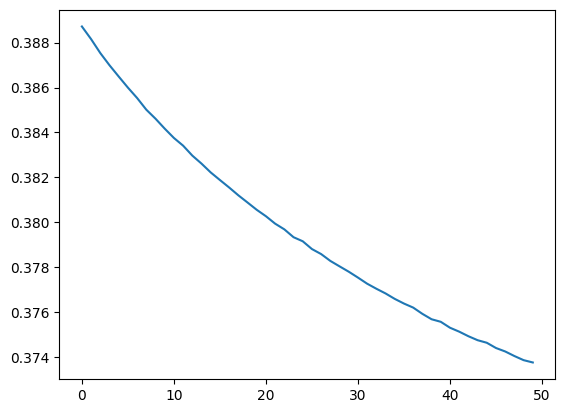

In [96]:
# Plotting graph of training loss

plt.plot(history.history['loss'])

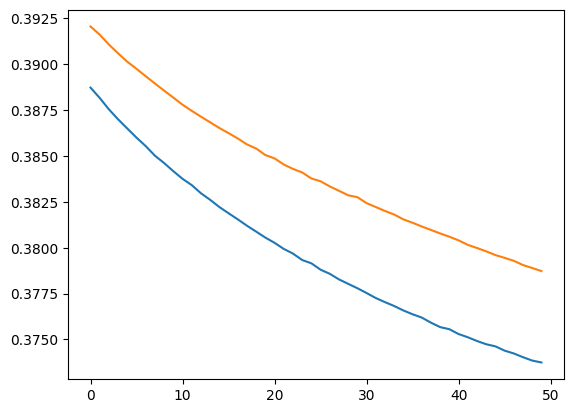

In [99]:
# comparing training and validation loss

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

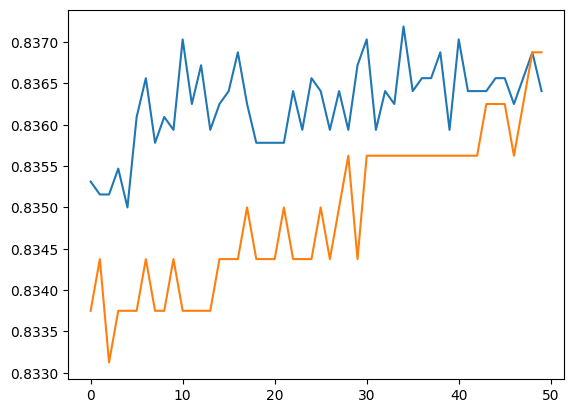

In [100]:
# We can also plot training acc and val_accuracy

# comparing training and val acc

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])